# 01 · Exploración por bloques (EDA)

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 1 · Análisis histórico (primer contacto con las variables de la tesis)

## A. Contexto de la etapa

**¿Qué investigamos?** Si la herencia del MC4 (geometría y temperatura) frente a la operación y los rodillos del Skinpass explica (A) el esfuerzo mecánico del Skinpass y su desviación frente al preset y (B) las retenciones por defecto físico.

**¿Por qué este análisis?** Un modelo solo puede aprender de la **variación que existe en los datos**. Si casi toda la variación de la corona es diferencia entre productos, controlar por producto dejará poco para explicar; si el Δ Fuerza apenas cambia entre piezas, no habrá nada que atribuirle al MC4. Antes de modelar hay que ver:
1. cómo se distribuye cada variable y qué tan limpia está;
2. **cuánta variación queda dentro de un mismo producto** (la que la tesis puede usar);
3. si hay señales de desgaste de rodillo, de tendencia en el tiempo o de cambios de régimen;
4. cuántos eventos tiene cada resultado del problema B con las definiciones aprobadas.

**¿Qué pregunta de la tesis atiende?** Todavía ninguna de forma causal. Responde una condición previa: *¿hay suficiente variación, en los lugares correctos, para que la pregunta tenga respuesta?*

**Decisiones del Notebook 00 que se aplican aquí** (ver `docs/plan_de_analisis.md`):
- Unidad: pieza del Skinpass ligada a su rollo del MC4. Problema A: solo **modo Elongación**.
- Retención **administrativa** = retenida solo por defectos de PESO.
- Problema B en dos partes: **B1** (retención por regla automática) y **B2** (defecto registrado por un inspector).

## B. Fundamento conceptual

**1. Variación entre y dentro de grupos.** La varianza total de una variable se puede partir en dos: la que se explica por la media de cada grupo (*entre* grupos) y la que queda alrededor de esa media (*dentro* de grupos). La fracción entre grupos es un R²:

$$R^2_{\text{grupo}} = 1 - \frac{\sum (y_i - \bar y_{g(i)})^2}{\sum (y_i - \bar y)^2}$$

Si `Producto` explica el 80 % de la corona, el 20 % restante es lo único que un modelo "controlado por producto" puede atribuir a otras causas. Con muchos grupos pequeños el R² se infla solo (cada grupo "se aprende" su propia media), por eso reportamos el **R² ajustado**, que penaliza el número de grupos.

**2. Robustez.** Las variables industriales traen valores imposibles (sensores, capturas). Por eso describimos con **mediana y percentiles** y marcamos como extremo lo que cae a más de 5 rangos intercuartílicos de la caja. No se borra nada aquí: solo se mide.

**3. Desgaste de rodillo.** En el Skinpass, un rodillo de trabajo se usa una campaña (~85 piezas), se retira, se **rectifica** (pierde diámetro) y vuelve. Dos escalas de desgaste:
- *dentro de la campaña*: piezas y toneladas acumuladas desde que se montó (rugosidad que se pierde);
- *vida del rodillo*: el diámetro, que baja con cada rectificado.

**4. Eventos raros.** Con pocos eventos (por ejemplo, 60 piezas con ondulación) cualquier tasa por subgrupo es muy ruidosa. Agrupar defectos con el mismo mecanismo físico en **familias** es la forma de tener eventos suficientes sin mezclar fenómenos distintos.

## C. Objetivo y metodología

| # | Análisis | Variables | Qué esperamos |
|---|---|---|---|
| 1 | Base de análisis | Piezas ligadas, modo, etiquetas B | Tamaño de cada población |
| 2 | Calidad por bloque | Respuestas, MC4 geometría y térmica, SKP rodillos, controles | Cobertura, ceros, extremos, valores sospechosos |
| 3 | Respuesta A | Real, preset y Δ de fuerza, bending y tensiones; elongación | Forma de las distribuciones; cuál Δ tiene variación |
| 4 | Bloque MC4 | Errores contra objetivo, corona, corona relativa, acuñamiento, taper, caída térmica | Rangos físicos; revisión de la regla de corona |
| 5 | Bloque SKP | Diámetro, campaña, posición en campaña | Señal de desgaste en el Δ |
| 6 | Entre y dentro de grupos | Producto, PRAM, Programa MC4, Programa SKP, campaña | Cuánta variación sobrevive al control por producto |
| 7 | Tiempo | Mediana semanal | Tendencias o cambios de régimen |
| 8 | Resultado B | Administrativa, B1, B2 por familia | Conteo de eventos y tasas |

**Técnicas:** estadística descriptiva robusta, descomposición de varianza por grupos (R² ajustado), gráficas. **No hay modelos ni correlaciones entre bloques** (eso es el Notebook 02).

**Variables derivadas.** Algunas (Δ, errores contra objetivo, corona relativa) se calculan aquí **solo para explorar**. Su definición formal, con el tratamiento de faltantes y extremos, es tarea del Notebook 03.

## D. Implementación
### 0. Configuración

In [2]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)   # siempre la última versión del repo
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [3]:
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
M = lambda c: f'{c} MC4'          # columnas del MC4 tras el join llevan el sufijo ' MC4'

### 1. Base de análisis
Partimos de las piezas del Skinpass ligadas a su rollo del MC4 (join desde el Skinpass; el Notebook 00 verificó que no multiplica filas). Las variables derivadas de esta celda son **exploratorias**.

In [4]:
mc4 = cargar_mc4()
skp = cargar_skp()
L = unir_mc4_skp(mc4, skp).sort_values('Fecha Inicio').reset_index(drop=True)

PF, RF = 'Preset Fuerza [kN]', 'Fuerza Real Prom.  [kN]'
PB, RB = 'Preset Bending', 'Bending Prom. Real [kN]'
PBk, RBk = 'Back Preset Tensión [kN]', 'Back Tensión Real Prom. [kN]'
PFr, RFr = 'Front Preset Tensión [kN]', 'Front Tensión Real Prom. [kN]'

X = pd.DataFrame(index=L.index)
# --- Respuesta A (Δ = Real − Preset)
X['ΔFuerza'] = L[RF] - L[PF]
X['ΔBending'] = L[RB] - L[PB]
X['ΔBack'] = L[RBk] - L[PBk]
X['ΔFront'] = L[RFr] - L[PFr]
X['Fuerza real'] = L[RF]
X['Elongación'] = L['Elongación']
# --- MC4 geometría (corona depurada con la regla 0-300 µm del Notebook 01 de antecedentes)
lo, hi = CORONA_VALIDA_UM
cor = L[M('Corona Salida')]
X['Corona (µm)'] = cor.where(cor.between(lo, hi))
X['Corona relativa (%)'] = 100 * X['Corona (µm)'] / (1000 * L[M('Espesor')])
X['Acuñamiento (µm)'] = L[M('Acuñamiento Salida')]
X['Taper medido'] = L[M('Taper Medido')]
X['Error espesor (µm)'] = 1000 * (L[M('Espesor')] - L[M('Espesor Objetivo')])
X['Error ancho (mm)'] = L[M('Ancho')] - L[M('Ancho Objetivo')]
X['Canteo R1'] = L[M('Canteo R1')]
X['Offset ancho manual'] = L[M('Offset de Ancho Manual ')]
# --- MC4 térmica
X['Error T enrollado (°C)'] = L[M('Temp Enrollado Real')] - L[M('Temp Enrollado Obj')]
X['Error T acabado (°C)'] = L[M('Temp Acabado Real')] - L[M('Temp Acabado Obj')]
X['Caída F1→F7 (°C)'] = L[M('Temp. F1')] - L[M('Temp. F7')]
X['Asimetría acabador (°C)'] = (L[M('Temp. Acabador Sup. A')] - L[M('Temp. Acabador Sup. B')]).abs()
X['Looper media (MPa)'] = L[[M(f'Tensión de Looper {i} [Mpa]') for i in range(1, 7)]].mean(axis=1)
X['Días MC4 → SKP'] = (L['Fecha Inicio'] - L[M('Fecha Fin')]).dt.total_seconds() / 86400
# --- SKP rodillos: campaña = racha contigua (en orden temporal) del mismo rodillo de trabajo
X['Campaña'] = (L['Rodillo de Trabajo'] != L['Rodillo de Trabajo'].shift()).cumsum()
X['Pieza en campaña'] = X.groupby('Campaña').cumcount() + 1
X['Toneladas en campaña'] = L.groupby(X['Campaña'])['Peso'].cumsum() / 1000
X['Diámetro rodillo (mm)'] = L['Rodillo de Trabajo Diám. Entrada']
X['Dif. diám. pareja (mm)'] = (L['Rodillo de Trabajo Diám. Entrada'] - L['Rodillo de Trabajo Pareja Diám. entrada']).abs()
# --- Controles y agrupaciones
X['Producto'] = (L['Norma'].astype(str) + ' | ' + L['Grado Salida'].astype(str) + ' | '
                 + pd.cut(L['Espesor Entrada'], CORTES_ESPESOR_MM).astype(str))
for c in ['PRAM', 'Grado Salida', 'Modo Molino', 'Dividido', 'Es Reproceso']:
    X[c] = L[c]
X['Programa SKP'] = L['Programa'].astype(str)
X['Programa MC4'] = L[M('Programa')].astype('Int64').astype(str)
X['Fecha'] = L['Fecha Inicio']
X['Peso (t)'] = L['Peso'] / 1000

A = X['Modo Molino'] == 'Elongación'
print(f'Piezas ligadas: {len(X):,}  ·  población A (modo Elongación): {A.sum():,}  ·  modo Fuerza: {(~A).sum():,}')
print(f"Productos (Norma | Grado Salida | rango de espesor): {X['Producto'].nunique():,}  ·  PRAM: {X['PRAM'].nunique()}  ·  campañas de rodillo: {X['Campaña'].nunique()}")

Piezas ligadas: 57,099  ·  población A (modo Elongación): 51,965  ·  modo Fuerza: 5,134
Productos (Norma | Grado Salida | rango de espesor): 818  ·  PRAM: 135  ·  campañas de rodillo: 668


In [6]:
# --- Etiquetas del resultado B con las definiciones aprobadas.
D = defectos_largo(L)
D['peso'] = D['d'].str.startswith('PESO')
FAMILIAS = {
    'Forma': ['TABLEADO', 'ONDULACIÓN', 'FUERA DE PLANEZA', 'DOBLEZ TRANSVERSAL', 'DOBLEZ PAÑUELO', 'AGLOBADO', 'COLA DE PESCADO'],
    'Superficie y manejo': ['MARCAS', 'SOMBRAS', 'RAYAS', 'PLASTAS', 'MALTRATO', 'MANCHAS DE GRASA Y/O ACEITE'],
    'Enrollado': ['MAL ENROLLADO', 'TELESCOPIADO', 'TENSIÓN DE ENROLLADO', 'COLEADO'],
    'Bordes': ['ORILLA DEFECTUOSA', 'PUNTA RASGADA', 'REVENTÓN'],
    'Metalúrgico (acería / MC4)': ['INCLUSIONES', 'ESCAMAS', 'ÓXIDO ROJO', 'ÓXIDO SIN DESCASCARADO', 'AGUJEROS',
                                   'FUERA DE PROPIEDADES MECANICAS', 'FALTA DE PROPIEDADES MECANICAS'],
}
fam_de = {d: f for f, ds in FAMILIAS.items() for d in ds}
D['familia'] = D['d'].map(fam_de)

R = D[D['ret'] & ~D['peso']]                       # defectos no-PESO que retienen
ret = L['Dictamen'].eq('RETENIDO')
solo_peso = ret & ~L.index.isin(R['row'])
B1 = L.index.isin(R.loc[R['a'] == 1, 'row']) | L.index.isin(R.loc[(R['a'] == 0) & R['familia'].isna() & R['d'].str.contains('ANCHO|ESPESOR|TEMPERATURA'), 'row'])
B2 = L.index.isin(R.loc[(R['a'] == 0) & R['familia'].notna(), 'row'])
X['Retenida'] = ret.values
X['Administrativa'] = solo_peso.values
X['B1'] = B1
X['B2'] = B2
for f in FAMILIAS:
    X[f'B2 · {f}'] = L.index.isin(R.loc[(R['a'] == 0) & (R['familia'] == f), 'row'])

resumenB = pd.Series({
    'Retenidas': ret.sum(), 'Administrativa (solo PESO)': solo_peso.sum(),
    'B1 · regla automática (o medición registrada por inspector)': B1.sum(),
    'B2 · defecto físico de inspector': B2.sum(), 'B1 y B2 a la vez': (B1 & B2).sum(),
    'Retenidas no-PESO sin B1 ni B2 (otros: muestra, equipo, identificación…)': (ret & ~solo_peso & ~B1 & ~B2).sum(),
}, name='piezas')
resumenB.to_frame()

,piezas
Retenidas,4072
Administrativa (solo PESO),1951
B1 · regla automática (o medición registrada por inspector),1504
B2 · defecto físico de inspector,685
B1 y B2 a la vez,75
"Retenidas no-PESO sin B1 ni B2 (otros: muestra, equipo, identificación…)",7


**Qué observamos.** Trabajamos con 57,099 piezas ligadas (97 % del Skinpass). La población A tiene 51,965 piezas en modo Elongación, repartidas en 818 productos y 668 campañas de rodillo. En las piezas ligadas hay 4,072 retenidas: 1,951 administrativas, 1,504 en B1 y 685 en B2. Del lado B, las etiquetas siguen las definiciones aprobadas:
- **Administrativa:** la pieza solo tiene defectos de PESO que retienen.
- **B1:** retención por regla automática. Incluye también los defectos de ANCHO, ESPESOR o TEMPERATURA que registró un inspector, porque se definen igual: una medición contra una tolerancia.
- **B2:** defecto físico observado por un inspector, agrupado en cinco familias según su mecanismo.

Una pieza puede estar en B1 y en B2 a la vez. Unas pocas retenciones (falta de muestra, falla de equipo, material mal identificado) no entran en ninguna: son incidencias, no calidad.

### 2. Calidad de los datos por bloque
Para cada variable del análisis: cobertura, porcentaje de ceros, valores distintos, percentiles y fracción de **extremos** (a más de 5 rangos intercuartílicos de la caja).

In [7]:
BLOQUES = {
    'Respuesta A': ['ΔFuerza', 'ΔBending', 'ΔBack', 'ΔFront', 'Fuerza real', 'Elongación'],
    'MC4 geometría': ['Corona (µm)', 'Corona relativa (%)', 'Acuñamiento (µm)', 'Taper medido', 'Error espesor (µm)',
                      'Error ancho (mm)', 'Canteo R1', 'Offset ancho manual'],
    'MC4 térmica': ['Error T enrollado (°C)', 'Error T acabado (°C)', 'Caída F1→F7 (°C)', 'Asimetría acabador (°C)',
                    'Looper media (MPa)', 'Días MC4 → SKP'],
    'SKP rodillos': ['Diámetro rodillo (mm)', 'Dif. diám. pareja (mm)', 'Pieza en campaña', 'Toneladas en campaña'],
}
def perfil(s):
    s = s.astype(float); v = s.dropna()
    q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
    ext = ((v < q1 - 5 * iqr) | (v > q3 + 5 * iqr)).mean() if iqr > 0 else np.nan
    return pd.Series({'cobertura %': 100 * s.notna().mean(), 'ceros %': 100 * (v == 0).mean(), 'distintos': v.nunique(),
                      'p1': v.quantile(.01), 'mediana': v.median(), 'p99': v.quantile(.99), 'extremos %': 100 * ext})
filas = []
for b, cols in BLOQUES.items():
    base = X[A] if b == 'Respuesta A' else X
    for c in cols:
        filas.append(perfil(base[c]).rename((b, c)))
calidad = pd.DataFrame(filas)
calidad.index = pd.MultiIndex.from_tuples(calidad.index, names=['bloque', 'variable'])
calidad.round(2).to_csv(RESULTADOS / '01_calidad_variables.csv')
calidad.round(1)

cobertura %  ceros %  distintos      p1  mediana     p99  extremos %
bloque        variable                                                                                     
Respuesta A   ΔFuerza                         99.9      0.0    39610.0 -3489.4   -814.6  2528.2         0.0
              ΔBending                        99.9      1.0     1374.0  -758.0    -39.0   266.0         0.1
              ΔBack                           99.9     13.8     5852.0   -65.6      0.0   126.1         9.3
              ΔFront                          99.9      2.7     2860.0   -89.5     -0.2    26.9        13.6
              Fuerza real                     99.9      0.0    28117.0  2420.0   3986.6  7028.0         0.0
              Elongación                     100.0      0.0    49922.0     1.1      1.5     2.8         0.0
MC4 geometría Corona (µm)                     95.7      0.0    28342.0    33.9     60.5   264.9         5.8
              Corona relativa (%)             95.7      0.0    46092.0     0.6      2.0     9.1         0.6
              Acuñamiento (µm)                97.7      0.0    30795.0   -59.0    -16.1    97.4         1.3
              Taper medido                    96.5     15.3      213.0   -38.0      0.0    30.0         4.2
              Error espesor (µm)             100.0      7.1      316.0    -2.0      2.0     7.0         0.2
              Error ancho (mm)               100.0      0.1     5058.0    -6.2      1.2    13.0         0.1
              Canteo R1                       99.7      0.4    25450.0     9.6     32.5    82.0         0.5
              Offset ancho manual             99.7     96.6       37.0    -2.0      0.0     1.0         NaN
MC4 térmica   Error T enrollado (°C)          99.9      0.0    17358.0  -130.2     -3.6     7.1         2.3
              Error T acabado (°C)            99.9      0.1     5549.0   -42.7     -3.4    17.2         0.8
              Caída F1→F7 (°C)                99.7      0.0    46778.0    55.5    103.7   135.8         0.0
              Asimetría acabador (°C)         99.2      8.4       35.0     0.0      3.0    15.0         0.1
              Looper media (MPa)              99.8      0.0     8900.0    10.5     18.6    27.1         0.0
              Días MC4 → SKP                 100.0      0.0    53604.0     3.5      5.3    24.6         2.2
SKP rodillos  Diámetro rodillo (mm)          100.0      0.0      373.0   402.0    425.8   450.1         0.0
              Dif. diám. pareja (mm)          97.9     46.2       13.0     0.0      0.1     0.2         0.2
              Pieza en campaña               100.0      0.0      285.0     1.0     46.0   189.0         0.0
              Toneladas en campaña           100.0      0.0    53845.0    27.2    958.6  3653.8         0.0

**Cómo leer la tabla.** *Cobertura* baja indica un bloque que perderá filas al modelar. Un *% de ceros* alto en una variable continua puede ser un valor "por defecto" del sistema. Con *extremos %* por encima de ~1 % conviene revisar el sensor antes de usar la variable.

In [8]:
# Valores sospechosos que el EDA debe registrar (no se corrigen aquí: se decide en el Notebook 03).
sosp = pd.Series({
    'Corona fuera de 0-300 µm (pasa a faltante)': (L[M('Corona Salida')].notna() & X['Corona (µm)'].isna()).sum(),
    'Acuñamiento |x| > 300 µm': (X['Acuñamiento (µm)'].abs() > 300).sum(),
    'Taper medido |x| > 200': (X['Taper medido'].abs() > 200).sum(),
    'Error T enrollado |x| > 100 °C': (X['Error T enrollado (°C)'].abs() > 100).sum(),
    'Error espesor |x| > 500 µm': (X['Error espesor (µm)'].abs() > 500).sum(),
    'Taper Teórico distinto de 0 (en todo el MC4)': (mc4['Taper Teórico'].fillna(0) != 0).sum(),
    'Espesor Final igual a Espesor medido (±0.01 mm)': int(np.isclose(L[M('Espesor Final')], L[M('Espesor')], atol=.01).sum()),
    'Espesor Final igual a Espesor Salida del SKP (±0.02 mm)': int(np.isclose(L[M('Espesor Final')], L['Espesor Salida'], atol=.02).sum()),
}, name='piezas')
sosp.to_frame()

,piezas
Corona fuera de 0-300 µm (pasa a faltante),1151
Acuñamiento |x| > 300 µm,72
Taper medido |x| > 200,49
Error T enrollado |x| > 100 °C,719
Error espesor |x| > 500 µm,42
Taper Teórico distinto de 0 (en todo el MC4),0
Espesor Final igual a Espesor medido (±0.01 mm),143
Espesor Final igual a Espesor Salida del SKP (±0.02 mm),39948


**Qué observamos (columnas que no significan lo que su nombre sugiere).**
- **`Taper Teórico` vale 0 en todo el MC4.** El "ΔTaper = medido − teórico" de la propuesta se reduce a `Taper Medido`.
- **`Espesor Final` no es una medición del MC4.** Casi nunca coincide con el espesor medido y en la mayoría de las piezas sí coincide con el espesor de salida del Skinpass: es el **espesor nominal del producto final** (valores redondos como 4.0, 3.5, 1.83). La propuesta la incluía en la herencia geométrica. Se reclasifica como **especificación del producto** (control) y la corona relativa se calcula con el espesor medido, `Espesor`.
- Acuñamiento y taper tienen colas largas, con cientos de valores físicamente dudosos. Se tratarán en el Notebook 03 con una regla fijada antes de modelar, como se hizo con la corona.

### 3. Respuesta A: preset, real y Δ
Solo piezas en modo Elongación. Arriba, preset contra real; abajo, la diferencia Δ = Real − Preset.

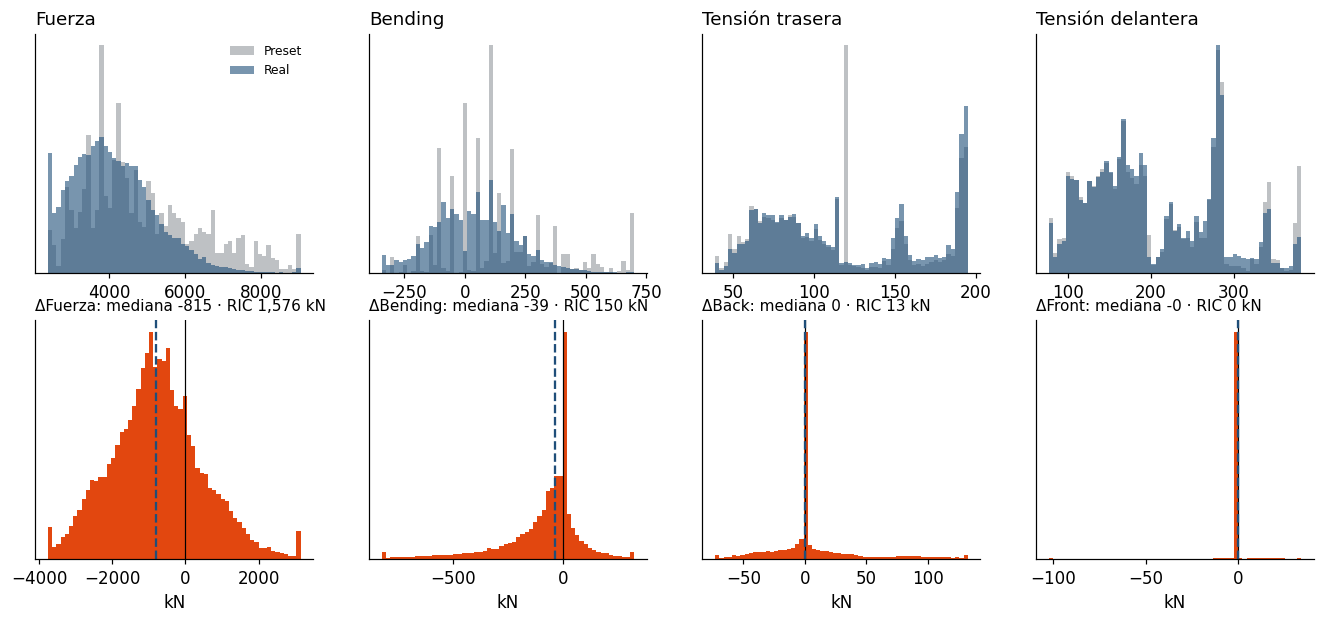

,mediana,RIC,% |Δ| < 5 kN,corr. preset-real
ΔFuerza,-814.6,1575.68,0.25,0.57
ΔBending,-39.0,150.00,11.47,0.56
ΔBack,0.0,12.70,48.73,0.70
ΔFront,-0.2,0.20,87.43,0.98


In [9]:
pares = [('Fuerza', PF, RF, 'ΔFuerza'), ('Bending', PB, RB, 'ΔBending'),
         ('Tensión trasera', PBk, RBk, 'ΔBack'), ('Tensión delantera', PFr, RFr, 'ΔFront')]
fig, ax = plt.subplots(2, 4, figsize=(15, 6.2))
for j, (n, p, r, d) in enumerate(pares):
    sub = L.loc[A, [p, r]].dropna()
    lo_, hi_ = sub.stack().quantile([.005, .995])
    bins = np.linspace(lo_, hi_, 60)
    ax[0, j].hist(sub[p].clip(lo_, hi_), bins, alpha=.55, color=COLORES['gris'], label='Preset')
    ax[0, j].hist(sub[r].clip(lo_, hi_), bins, alpha=.6, color=COLORES['azul'], label='Real')
    ax[0, j].set_title(n); ax[0, j].set_yticks([])
    v = X.loc[A, d].dropna(); a_, b_ = v.quantile([.005, .995])
    ax[1, j].hist(v.clip(a_, b_), 60, color=COLORES['naranja'])
    ax[1, j].axvline(0, color='k', lw=.8); ax[1, j].axvline(v.median(), color=COLORES['azul'], ls='--')
    ax[1, j].set_title(f'{d}: mediana {v.median():,.0f} · RIC {v.quantile(.75) - v.quantile(.25):,.0f} kN', fontsize=10)
    ax[1, j].set_yticks([]); ax[1, j].set_xlabel('kN')
ax[0, 0].legend(fontsize=8)
guardar(fig, '01_respuesta_A'); plt.show()

tabA = pd.DataFrame({d: {'mediana': X.loc[A, d].median(), 'RIC': X.loc[A, d].quantile(.75) - X.loc[A, d].quantile(.25),
                         '% |Δ| < 5 kN': 100 * (X.loc[A, d].abs() < 5).mean(),
                         'corr. preset-real': L.loc[A, [p, r]].corr().iloc[0, 1]} for _, p, r, d in pares}).T
tabA.round(2)

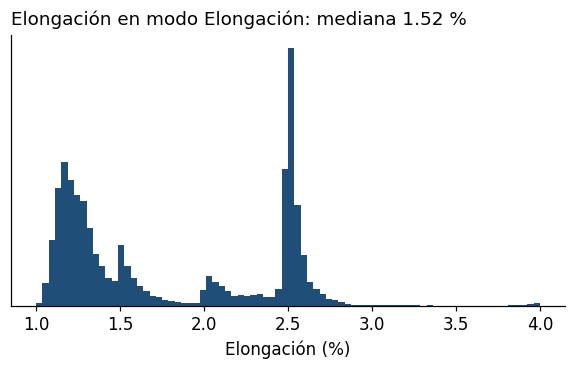

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
e = X.loc[A, 'Elongación'].dropna()
ax.hist(e.clip(0, 4), 80, color=COLORES['azul']); ax.set_xlabel('Elongación (%)'); ax.set_yticks([])
ax.set_title(f'Elongación en modo Elongación: mediana {e.median():.2f} %')
guardar(fig, '01_elongacion'); plt.show()

**Qué observamos.**
- **Fuerza:** Δ con mediana −815 kN y rango intercuartílico de 1,576 kN; correlación preset–real de 0.57. Es la respuesta con más variación.
- **Bending:** Δ con mediana −39 kN y rango intercuartílico de 150 kN; correlación 0.56.
- **Tensión delantera:** sigue al preset casi exactamente (correlación 0.98, rango intercuartílico de 0.2 kN). No hay nada que explicar.
- **Tensión trasera:** el 49 % de las piezas tiene |Δ| < 5 kN y hay un 9 % de extremos (los topes vistos antes). Poca variación útil.
- **Elongación:** mediana 1.5 %, casi toda entre 1.1 % y 2.8 %.

**Qué no podemos afirmar.** Que un Δ grande sea "malo". Puede reflejar un preset mal calibrado para cierto producto más que un rollo problemático. Lo separa el análisis dentro de producto (sección 6).

**Decisión preliminar.** Las respuestas principales del Problema A serán **Δ Fuerza y Δ Bending** (con sus valores Real en paralelo). Las tensiones se reportan como secundarias.

### 4. Bloque MC4: geometría y temperatura heredadas
Distribuciones de las variables de herencia, sin extremos (percentiles 0.5 a 99.5) para que se vea la forma.

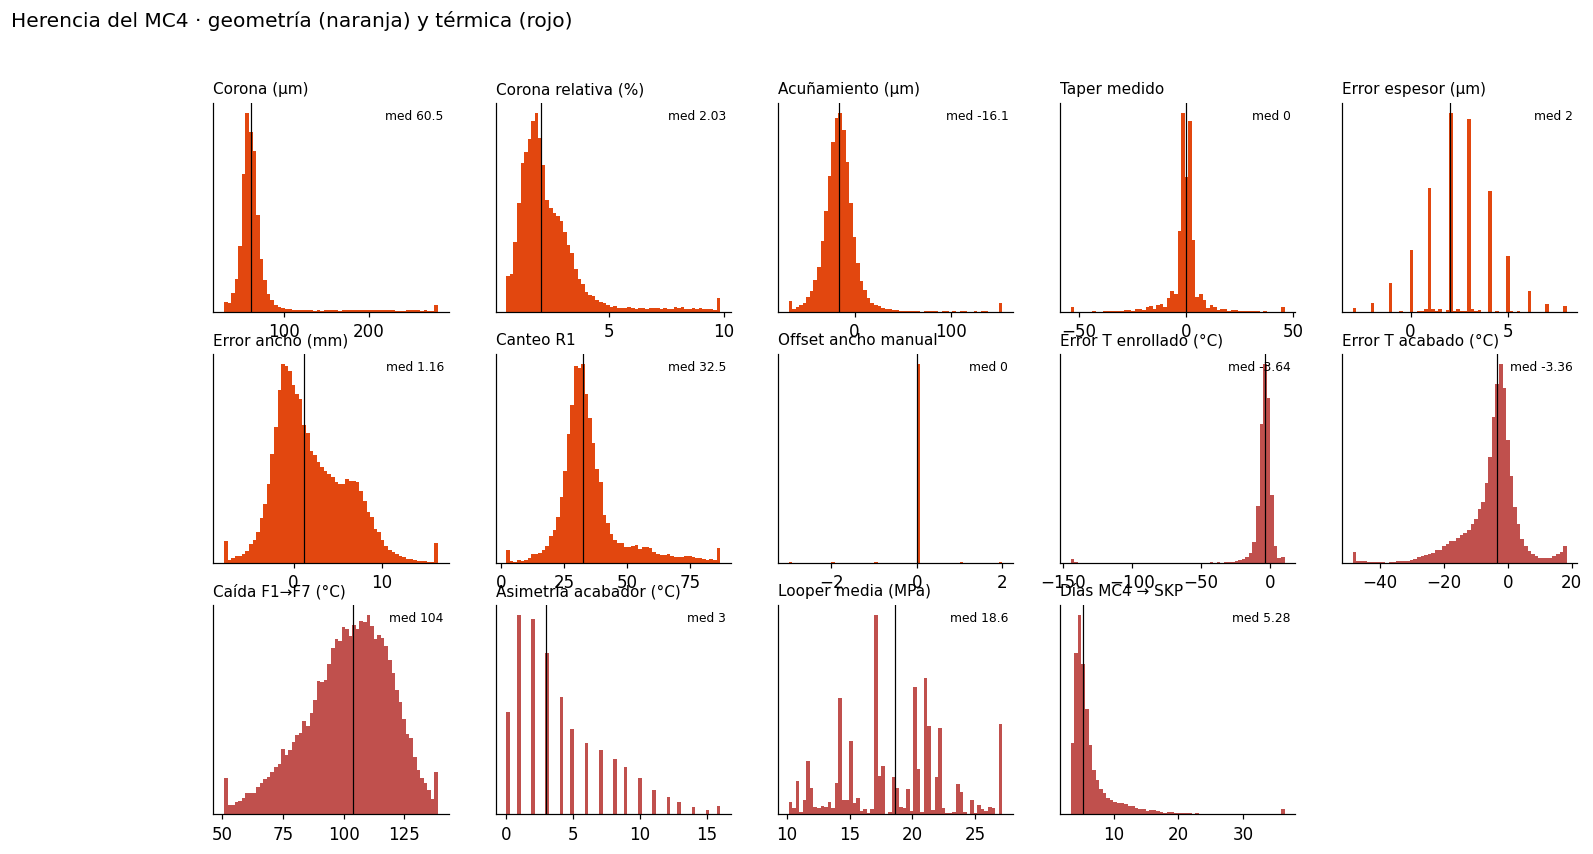

In [11]:
vars_mc4 = BLOQUES['MC4 geometría'] + BLOQUES['MC4 térmica']
fig, ax = plt.subplots(3, 5, figsize=(16, 8.4)); ax = ax.ravel()
for i, c in enumerate(vars_mc4):
    v = X[c].dropna(); a_, b_ = v.quantile([.005, .995])
    ax[i].hist(v.clip(a_, b_), 60, color=COLORES['naranja'] if i < 8 else COLORES['rojo'])
    ax[i].axvline(v.median(), color='k', lw=.8)
    ax[i].set_title(c, fontsize=10); ax[i].set_yticks([])
    ax[i].text(.98, .92, f'med {v.median():.3g}', transform=ax[i].transAxes, ha='right', fontsize=8)
for j in range(len(vars_mc4), len(ax)): ax[j].axis('off')
fig.suptitle('Herencia del MC4 · geometría (naranja) y térmica (rojo)', x=.01, ha='left')
guardar(fig, '01_bloque_mc4'); plt.show()

**¿La regla de corona 0-300 µm es correcta?** Se fijó en la Entrega 1 para quitar valores imposibles (±8,700 µm). Pero la corona depende del espesor: en lámina gruesa una corona de 400 µm puede ser real. Revisamos cuántas coronas entre 300 y 1,000 µm hay por rango de espesor.

In [12]:
c_raw = L[M('Corona Salida')]
rango = pd.cut(L[M('Espesor')], CORTES_ESPESOR_MM)
rev = pd.DataFrame({
    'piezas': c_raw.groupby(rango, observed=True).size(),
    'corona mediana (µm)': c_raw.where(c_raw.between(0, 1000)).groupby(rango, observed=True).median(),
    '% entre 300 y 1000 µm': 100 * c_raw.between(300, 1000).groupby(rango, observed=True).mean(),
    '% fuera de 0-1000 µm': 100 * (~c_raw.between(0, 1000) & c_raw.notna()).groupby(rango, observed=True).mean(),
})
rev.round(1)

,piezas,corona mediana (µm),% entre 300 y 1000 µm,% fuera de 0-1000 µm
Espesor MC4,,,,
"(0.0, 1.5]",975,56.7,0.0,0.0
"(1.5, 2.0]",8229,59.6,0.0,0.0
"(2.0, 2.5]",6949,62.5,0.0,0.0
"(2.5, 3.0]",9622,59.2,0.2,0.0
"(3.0, 4.0]",16095,60.4,1.2,0.0
"(4.0, 5.0]",9251,63.3,4.6,0.1
"(5.0, 6.0]",2669,61.9,5.9,0.1
"(6.0, 8.0]",2621,62.6,10.6,0.3
"(8.0, 13.0]",688,56.0,7.0,0.6


**Qué observamos.**
- **El MC4 cumple sus consignas con muy poca dispersión.** El error de espesor va de −2 a +7 µm (p1 a p99) y el de enrollado tiene mediana −3.6 °C. El de enrollado tiene una cola fría: 719 piezas a más de 100 °C del objetivo.
- **La variación heredada está en la forma del perfil:** corona (mediana 60 µm), corona relativa (mediana 2 % del espesor), acuñamiento y caída térmica entre castillos (mediana 104 °C).
- **La regla de corona 0-300 µm recorta coronas plausibles en lámina gruesa.** El porcentaje de coronas entre 300 y 1,000 µm sube con el espesor: 0 % bajo 2.5 mm, 4.6 % entre 4 y 5 mm, 10.6 % entre 6 y 8 mm. Los valores realmente imposibles (fuera de 0-1,000 µm) son menos del 0.6 % en cualquier rango. **Decisión para el Notebook 03:** la regla pasa a ser relativa al espesor (o a 0-1,000 µm) en lugar de 0-300 µm fijo.

### 5. Bloque Skinpass: rodillos y desgaste
Primero comprobamos cómo se comporta el diámetro de un rodillo a lo largo del año. Después, si el Δ cambia a medida que avanza la campaña, una vez quitada la diferencia entre productos.

Campañas: 668 · piezas por campaña: mediana 84, p90 135
Campañas con un solo diámetro registrado: 100.0%


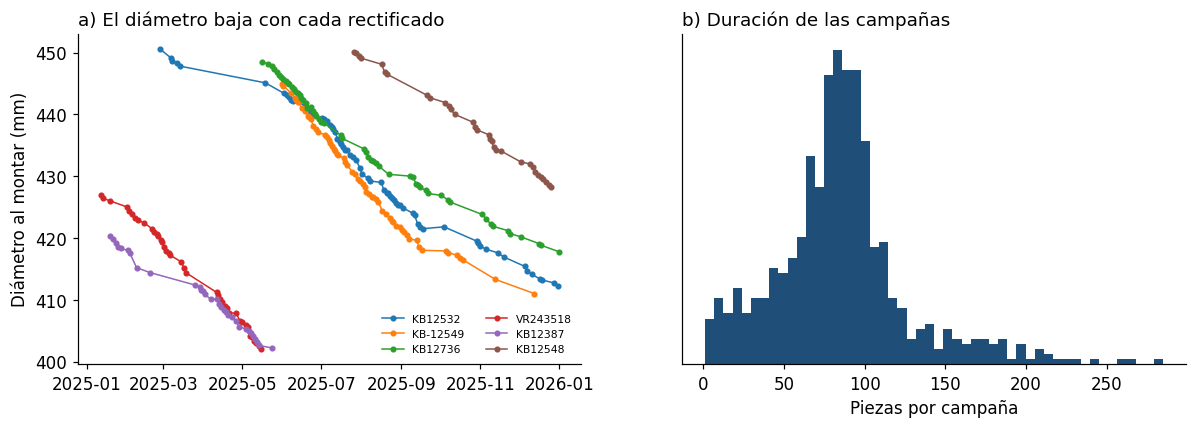

In [13]:
camp = X.groupby('Campaña').agg(rodillo=('Diámetro rodillo (mm)', 'size'), diam_distintos=('Diámetro rodillo (mm)', 'nunique'),
                                inicio=('Fecha', 'min'), diam=('Diámetro rodillo (mm)', 'first'))
camp['rodillo_id'] = L.groupby(X['Campaña'])['Rodillo de Trabajo'].first()
print(f"Campañas: {len(camp)} · piezas por campaña: mediana {camp.rodillo.median():.0f}, p90 {camp.rodillo.quantile(.9):.0f}")
print(f"Campañas con un solo diámetro registrado: {(camp.diam_distintos == 1).mean():.1%}")

top = camp.rodillo_id.value_counts().index[:6]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for i, r_ in enumerate(top):
    c_ = camp[camp.rodillo_id == r_]
    ax[0].plot(c_.inicio, c_.diam, 'o-', ms=3, lw=1, label=r_)
ax[0].set_ylabel('Diámetro al montar (mm)'); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_title('a) El diámetro baja con cada rectificado')
ax[1].hist(camp.rodillo.clip(upper=400), 50, color=COLORES['azul'])
ax[1].set_xlabel('Piezas por campaña'); ax[1].set_yticks([])
ax[1].set_title('b) Duración de las campañas')
guardar(fig, '01_rodillos'); plt.show()

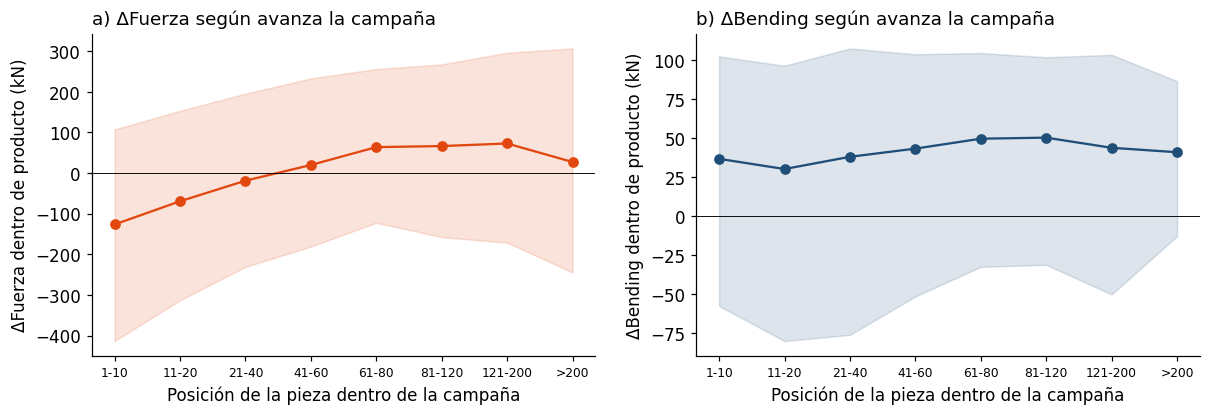

In [14]:
# Δ a lo largo de la campaña, quitando la media de cada producto (para no confundir con la mezcla de producto).
def dentro(col, grupo='Producto', datos=None):
    d = X if datos is None else datos
    return d[col] - d.groupby(grupo)[col].transform('mean')

xa = X[A].copy()
xa['tramo'] = pd.cut(xa['Pieza en campaña'], [0, 10, 20, 40, 60, 80, 120, 200, 2000],
                     labels=['1-10', '11-20', '21-40', '41-60', '61-80', '81-120', '121-200', '>200'])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for k, (col, c_) in enumerate([('ΔFuerza', COLORES['naranja']), ('ΔBending', COLORES['azul'])]):
    xa['aj'] = dentro(col, datos=xa)
    g = xa.groupby('tramo', observed=True)['aj'].agg(['median', lambda s: s.quantile(.25), lambda s: s.quantile(.75), 'size'])
    g.columns = ['med', 'q1', 'q3', 'n']
    ax[k].fill_between(range(len(g)), g.q1, g.q3, color=c_, alpha=.15)
    ax[k].plot(range(len(g)), g.med, 'o-', color=c_)
    ax[k].axhline(0, color='k', lw=.6)
    ax[k].set_xticks(range(len(g))); ax[k].set_xticklabels(g.index, fontsize=8)
    ax[k].set_xlabel('Posición de la pieza dentro de la campaña'); ax[k].set_ylabel(f'{col} dentro de producto (kN)')
    ax[k].set_title(f'{"ab"[k]}) {col} según avanza la campaña')
guardar(fig, '01_desgaste_delta'); plt.show()

**Qué observamos.**
- El diámetro es **constante dentro de cada campaña**: se registra al montar el rodillo. Baja de una campaña a la siguiente del mismo rodillo (rectificado). El diámetro mide la *vida* del rodillo; el desgaste *dentro* de la campaña solo se puede aproximar con piezas o toneladas acumuladas.
- **ΔFuerza sube a lo largo de la campaña.** Dentro de producto pasa de unos −125 kN en las primeras 10 piezas a +65 kN después de la pieza 60, una diferencia de ~190 kN, y luego se estabiliza. Con el rodillo recién montado, el Skinpass necesita menos fuerza de la que predice el preset; con el rodillo usado, más.
- **ΔBending casi no cambia** con la posición en la campaña: mediana entre +30 y +50 kN en todo el recorrido.

**Cómo interpretarlo.** Es una primera señal a favor del **experimento natural de desgaste** (Notebook 07). Un rodillo que pierde rugosidad cambia la fricción y la fuerza necesaria para la misma elongación. El tamaño del efecto (~190 kN) es pequeño frente a la dispersión pieza a pieza (banda de ±250 kN), pero sistemático.

**Qué no podemos afirmar.** Que una tendencia sea efecto del desgaste. Dentro de la campaña también cambian el orden de los anchos y el tipo de material que se programa, y el ajuste por producto no quita todo.

### 6. ¿Cuánta variación queda dentro de un mismo producto?
Para cada variable calculamos qué fracción de su varianza explican las medias de cada agrupación (R² ajustado). La columna clave es **1 − R²(Producto)**: lo que queda para la tesis después de controlar por producto.

In [15]:
def r2_ajustado(y, g):
    ok = y.notna() & g.notna()
    y, g = y[ok].astype(float), g[ok]
    n, k = len(y), g.nunique()
    r2 = r2_por_grupo(y, g)
    return 1 - (1 - r2) * (n - 1) / (n - k) if n > k else np.nan

GRUPOS_R2 = ['Producto', 'PRAM', 'Programa MC4', 'Programa SKP', 'Campaña']
VARS_R2 = ['ΔFuerza', 'ΔBending', 'ΔBack', 'Fuerza real', 'Elongación',
           'Corona (µm)', 'Corona relativa (%)', 'Acuñamiento (µm)', 'Error ancho (mm)', 'Error espesor (µm)',
           'Error T enrollado (°C)', 'Error T acabado (°C)', 'Caída F1→F7 (°C)']
base = X[A]
var_tab = pd.DataFrame({g: {v: r2_ajustado(base[v], base[g].astype(str)) for v in VARS_R2} for g in GRUPOS_R2})
var_tab['dentro de producto'] = 1 - var_tab['Producto']
var_tab.to_csv(RESULTADOS / '01_varianza_entre_dentro.csv')
(100 * var_tab).round(0)

,Producto,PRAM,Programa MC4,Programa SKP,Campaña,dentro de producto
ΔFuerza,84.0,48.0,24.0,13.0,12.0,16.0
ΔBending,7.0,4.0,10.0,22.0,21.0,93.0
ΔBack,24.0,8.0,7.0,-0.0,-1.0,76.0
Fuerza real,62.0,32.0,31.0,20.0,19.0,38.0
Elongación,95.0,83.0,28.0,13.0,13.0,5.0
Corona (µm),9.0,6.0,44.0,33.0,31.0,91.0
Corona relativa (%),32.0,9.0,46.0,31.0,30.0,68.0
Acuñamiento (µm),13.0,3.0,26.0,14.0,11.0,87.0
Error ancho (mm),35.0,19.0,19.0,13.0,12.0,65.0
Error espesor (µm),38.0,0.0,1.0,1.0,1.0,62.0


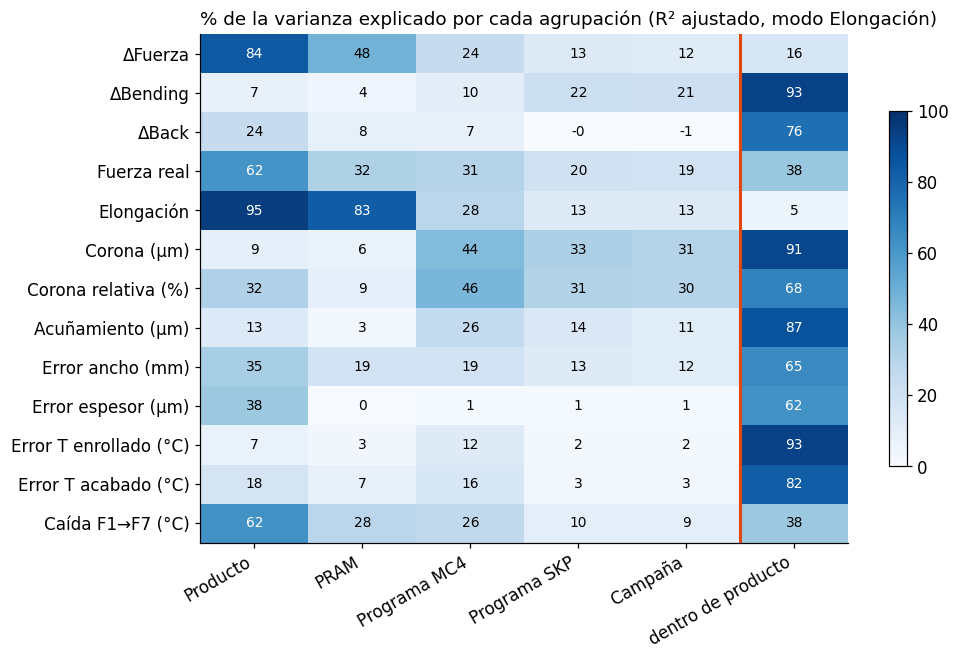

In [16]:
fig, ax = plt.subplots(figsize=(9.5, 6))
m = 100 * var_tab
im = ax.imshow(m.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(m.columns, rotation=30, ha='right')
ax.set_yticks(range(m.shape[0])); ax.set_yticklabels(m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.iat[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9, color='white' if v > 55 else 'black')
ax.axvline(len(GRUPOS_R2) - .5, color=COLORES['naranja'], lw=2)
ax.set_title('% de la varianza explicado por cada agrupación (R² ajustado, modo Elongación)')
fig.colorbar(im, ax=ax, shrink=.7)
guardar(fig, '01_varianza_grupos'); plt.show()

**Cómo leer el mapa.** Cada celda dice qué porcentaje de la variación de la variable (fila) desaparece si conocemos el grupo (columna). La última columna, separada por la línea naranja, es lo que queda **dentro de producto**: la variación que la tesis puede intentar explicar con la herencia del MC4 y la operación del Skinpass.

**Qué observamos.** Este es el hallazgo más importante del notebook:
- **ΔFuerza es sobre todo una cuestión de producto.** El producto explica el 84 % de su varianza y solo queda un 16 % dentro de producto. El setup se equivoca de forma distinta, pero consistente, para cada producto: es un **sesgo de calibración por producto**, no algo que cambie pieza a pieza.
- **ΔBending es lo contrario.** El producto explica solo el 7 % y el 93 % queda dentro de producto. El Programa SKP y la campaña explican ~21 %: buena parte del desvío del bending es "de turno y rodillo".
- **La herencia del MC4 varía dentro de producto.** La corona tiene el 91 % de su varianza dentro de producto, el acuñamiento el 87 % y los errores térmicos más del 80 %. El Programa MC4 explica el 44 % de la corona: la geometría heredada viaja por el programa del molino caliente.
- **La elongación la fija el producto** (95 %): es la consigna, no una respuesta.

**Implicación para la tesis.** La pregunta "¿la herencia del MC4 explica el esfuerzo?" tiene un **terreno fértil en ΔBending** (mucha variación dentro de producto que coincide con variación heredada) y un **terreno estrecho en ΔFuerza** (solo el 16 % dentro de producto). Para la fuerza, el hallazgo útil para planta es que el preset tiene un **sesgo por producto** que se podría corregir directamente.

**Advertencia.** Programa MC4, Programa SKP y Campaña tienen cientos de grupos. Aun ajustado, un R² alto puede reflejar que el grupo sigue al producto, no un efecto propio. Eso lo separan los modelos mixtos del Notebook 04.

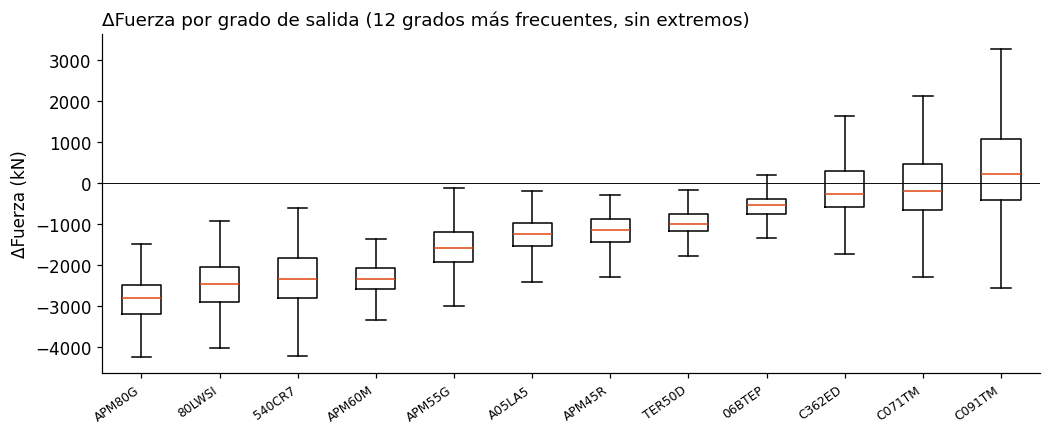

In [17]:
# Δ Fuerza por grado de salida (los 12 más frecuentes): ¿la diferencia entre productos domina?
top_g = X.loc[A, 'Grado Salida'].value_counts().index[:12]
sub = X[A & X['Grado Salida'].isin(top_g)]
orden = sub.groupby('Grado Salida')['ΔFuerza'].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([sub.loc[sub['Grado Salida'] == g, 'ΔFuerza'].dropna() for g in orden], showfliers=False,
           medianprops=dict(color=COLORES['naranja']))
ax.set_xticks(range(1, len(orden) + 1)); ax.set_xticklabels(orden, rotation=35, ha='right', fontsize=8)
ax.axhline(0, color='k', lw=.6); ax.set_ylabel('ΔFuerza (kN)')
ax.set_title('ΔFuerza por grado de salida (12 grados más frecuentes, sin extremos)')
guardar(fig, '01_delta_por_grado'); plt.show()

### 7. Evolución en el tiempo
Mediana semanal de las respuestas y de la herencia del MC4. Un cambio brusco podría ser un ajuste del modelo de setup o de la operación, y obligaría a validar por periodos.

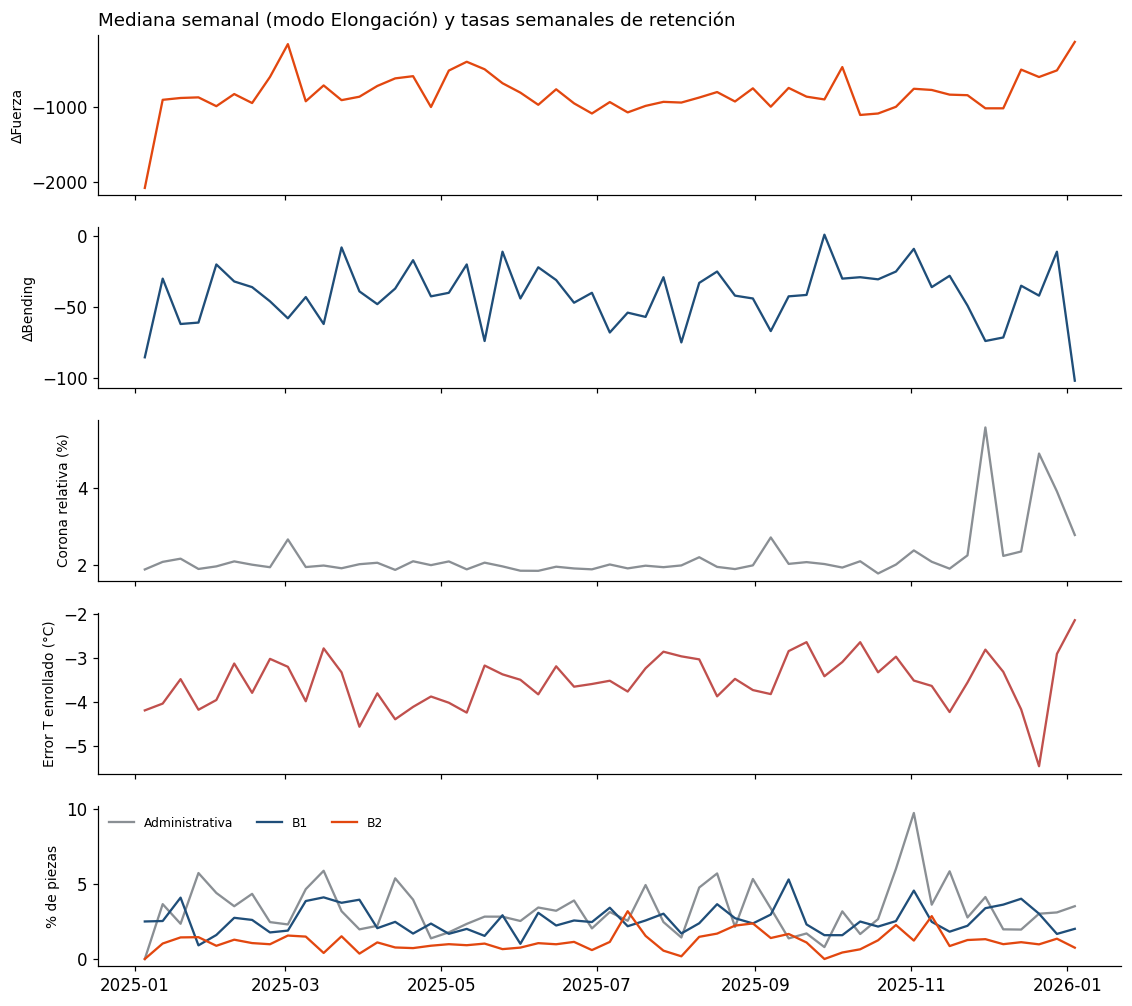

In [18]:
sem = X[A].set_index('Fecha').resample('W')
serie = pd.DataFrame({c: sem[c].median() for c in ['ΔFuerza', 'ΔBending', 'Corona relativa (%)', 'Error T enrollado (°C)']})
tasa = X.set_index('Fecha').resample('W')[['Administrativa', 'B1', 'B2']].mean() * 100
fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for i, c in enumerate(serie.columns):
    ax[i].plot(serie.index, serie[c], color=[COLORES['naranja'], COLORES['azul'], COLORES['gris'], COLORES['rojo']][i])
    ax[i].set_ylabel(c, fontsize=9)
for c, col in zip(tasa.columns, [COLORES['gris'], COLORES['azul'], COLORES['naranja']]):
    ax[4].plot(tasa.index, tasa[c], label=c, color=col)
ax[4].set_ylabel('% de piezas', fontsize=9); ax[4].legend(fontsize=8, ncol=3)
ax[0].set_title('Mediana semanal (modo Elongación) y tasas semanales de retención')
guardar(fig, '01_tiempo'); plt.show()

**Qué observamos.**
- **No hay escalones sostenidos.** ΔFuerza se mantiene alrededor de −900 kN y ΔBending entre −70 y −10 kN durante todo el año. La primera semana de enero y la última de diciembre tienen pocas piezas y no se interpretan.
- La corona relativa muestra picos en diciembre, probablemente por la mezcla de producto de esas semanas.
- La retención administrativa tiene un pico a inicios de noviembre (~10 %), compatible con un problema de asignación puntual y no con un cambio del proceso.

**Implicación para la validación.** El proceso es estable en el año, así que un corte temporal es una prueba justa de generalización, no una prueba contra un cambio de régimen. Se mantiene como validación secundaria.

### 8. Resultado B: eventos disponibles

In [17]:
famB2 = pd.Series({f: X[f'B2 · {f}'].sum() for f in FAMILIAS}, name='piezas').sort_values(ascending=False)
tasas = pd.Series({'Administrativa': X['Administrativa'].mean(), 'B1': X['B1'].mean(), 'B2': X['B2'].mean(),
                   **{f'B2 · {f}': X[f'B2 · {f}'].mean() for f in FAMILIAS}}) * 100
print('Tasa por pieza (%):'); print(tasas.round(2).to_string())

# Origen (Linea Origen) de los defectos B2
orig = R[(R['a'] == 0) & R['familia'].notna()].assign(o=lambda d: d['linea'].map({'SKP_PSQ': 'SKP', 'MC4_PSQ': 'MC4'}).fillna('otra'))
print('\nB2 por familia y línea de origen (piezas):')
print(orig.groupby(['familia', 'o']).row.nunique().unstack(fill_value=0).to_string())

Tasa por pieza (%):
Administrativa                     3.42
B1                                 2.63
B2                                 1.20
B2 · Forma                         0.27
B2 · Superficie y manejo           0.36
B2 · Enrollado                     0.46
B2 · Bordes                        0.01
B2 · Metalúrgico (acería / MC4)    0.12

B2 por familia y línea de origen (piezas):
o                           MC4  SKP
familia                             
Bordes                        6    2
Enrollado                    13  248
Forma                        69   89
Metalúrgico (acería / MC4)   69    1
Superficie y manejo          64  144


In [18]:
# Los rollos que excedían el peso máximo de la orden y no se dividieron (hallazgo del Notebook 00).
rol = L.groupby('Material Entrada').agg(PE=('Peso Entrada', 'first'), PMax=('Peso Máximo', 'first'), div=('Dividido', 'first'))
grupo = np.select([(rol.PE > rol.PMax) & (rol['div'] == 'NO'), (rol.PE > rol.PMax) & (rol['div'] == 'SI')],
                  ['Excede y NO se divide', 'Excede y se divide'], 'Cabe en la orden')
X['Peso vs orden'] = L['Material Entrada'].map(pd.Series(grupo, index=rol.index)).values
peso_mas = L.index.isin(D.loc[D['ret'] & (D['d'] == 'PESO (+)'), 'row'])
peso_menos = L.index.isin(D.loc[D['ret'] & (D['d'] == 'PESO (-)'), 'row'])
tab_peso = pd.DataFrame({'piezas': X.groupby('Peso vs orden').size(),
                         'retenida PESO (+) %': 100 * pd.Series(peso_mas, index=X.index).groupby(X['Peso vs orden']).mean(),
                         'retenida PESO (-) %': 100 * pd.Series(peso_menos, index=X.index).groupby(X['Peso vs orden']).mean()})
tab_peso.round(1)

,piezas,retenida PESO (+) %,retenida PESO (-) %
Peso vs orden,,,
Cabe en la orden,38428,0.0,1.6
Excede y NO se divide,2061,51.2,1.1
Excede y se divide,16610,0.3,3.8


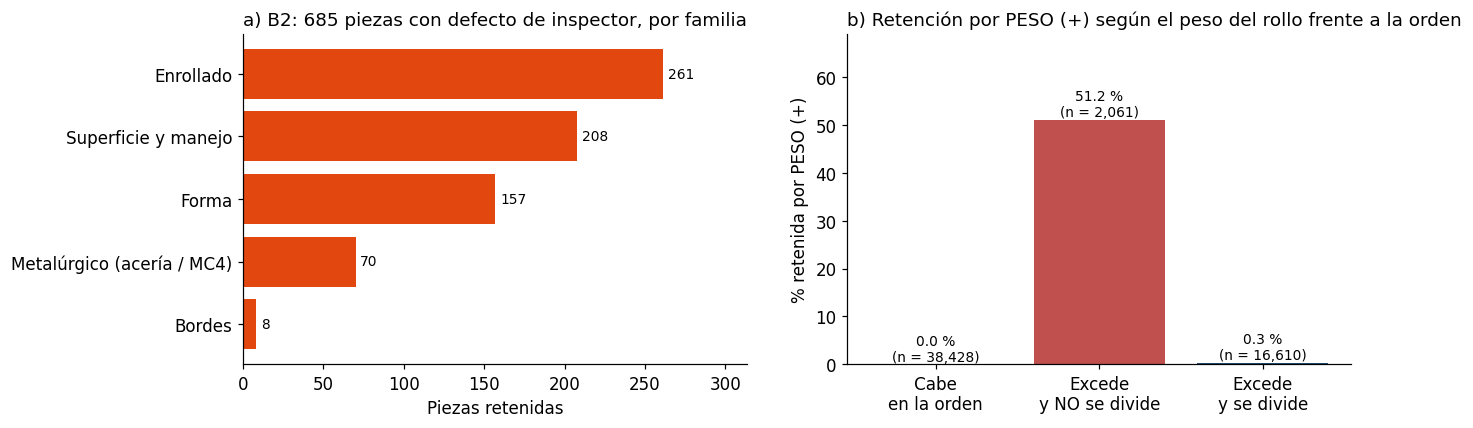

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ax[0].barh(famB2.index[::-1], famB2.values[::-1], color=COLORES['naranja'])
for i, v in enumerate(famB2.values[::-1]):
    ax[0].text(v + 3, i, f'{v}', va='center', fontsize=9)
ax[0].set_xlabel('Piezas retenidas'); ax[0].set_title(f'a) B2: {X.B2.sum()} piezas con defecto de inspector, por familia')
ax[0].set_xlim(0, famB2.max() * 1.2)
t = tab_peso['retenida PESO (+) %']
ax[1].bar(t.index, t.values, color=[COLORES['gris'], COLORES['rojo'], COLORES['azul']])
for i, (v, n) in enumerate(zip(t.values, tab_peso.piezas)):
    ax[1].text(i, v, f'{v:.1f} %\n(n = {n:,})', ha='center', va='bottom', fontsize=9)
ax[1].set_xticks(range(len(t))); ax[1].set_xticklabels([i.replace(' y ', '\ny ').replace(' en ', '\nen ') for i in t.index])
ax[1].set_ylabel('% retenida por PESO (+)'); ax[1].set_ylim(0, t.max() * 1.35)
ax[1].set_title('b) Retención por PESO (+) según el peso del rollo frente a la orden')
guardar(fig, '01_resultado_B'); plt.show()

**Qué observamos.**
- **B2 tiene pocos eventos:** 685 piezas (1.2 %). Por familia: enrollado 0.46 %, superficie y manejo 0.36 %, forma 0.27 % (157 piezas), metalúrgico 0.12 %, bordes 0.01 %. Bordes no tiene eventos suficientes para analizarse sola.
- **La línea de origen coincide con el mecanismo:** enrollado es casi todo de origen Skinpass (248 de 261), metalúrgico casi todo MC4 (69 de 70) y superficie mayormente Skinpass. **Forma está repartida** (89 Skinpass, 69 MC4): es la familia donde la herencia del MC4 y la operación del Skinpass se cruzan, justo la que la tesis quiere separar.
- **Peso, el hallazgo más fuerte del notebook.** Los rollos que excedían el peso máximo de su orden y **no se dividieron** (2,061 piezas) se retuvieron por PESO (+) en el **51 %** de los casos. Los que cabían en la orden: 0.0 %. Los que excedían y sí se dividieron: 0.3 %. Prácticamente toda la retención por PESO (+) sale de ese grupo. Es evidencia directa a favor de la **intervención A**.

**Qué no podemos afirmar.** Que todo PESO (+) se evitaría dividiendo. Algunos rollos quizá no se podían dividir (peso mínimo de la orden, longitud). Eso se estudia al diseñar la intervención.

## F. Conclusiones de la etapa

### Hallazgos principales
1. **ΔFuerza es un sesgo del setup por producto** (84 % de su varianza entre productos). Solo el 16 % queda dentro de producto para la herencia del MC4.
2. **ΔBending varía dentro de producto** (93 %) y en parte por turno y campaña de rodillo (~21 %). Es la respuesta A con más terreno para la tesis.
3. **Las tensiones casi no se desvían** del preset (la delantera, nada). Pasan a respuestas secundarias.
4. **La herencia del MC4 sí varía dentro de producto** (corona 91 %, acuñamiento 87 %, errores térmicos > 80 %), aunque los errores contra objetivo son pequeños en valor absoluto.
5. **Señal de desgaste:** ΔFuerza sube ~190 kN entre el inicio de la campaña y la pieza 60, dentro de producto. ΔBending no cambia.
6. **Peso:** el 51 % de las piezas de rollos que excedían la orden y no se dividieron se retuvo por PESO (+), contra 0 % del resto. Evidencia directa para la intervención A.
7. **B2:** 685 eventos. La familia **Forma** (157) es la única repartida entre origen MC4 y Skinpass.
8. **Columnas que no son lo que parecen:** `Taper Teórico` siempre vale 0 y `Espesor Final` es el espesor nominal del producto final. La regla de corona 0-300 µm recorta coronas reales en lámina gruesa.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Respuestas A | ΔBending principal; ΔFuerza principal **dentro de producto** (efecto fijo de producto obligatorio); tensiones secundarias |
| Regla de corona | Pasa a ser relativa al espesor (se fija en el Notebook 03) |
| Desgaste | Piezas y toneladas en campaña entran al bloque SKP; candidato fuerte para el Notebook 07 |
| `Espesor Final` | Se reclasifica como especificación del producto (control), no herencia |
| `Taper Teórico` | Se descarta; ΔTaper = `Taper Medido` |
| Corona relativa | Se calcula con el espesor medido (`Espesor`) |
| Familias de B2 | Forma, superficie y manejo, enrollado, bordes, metalúrgico |

### Limitaciones
- Las variables derivadas de este notebook son exploratorias: el tratamiento formal de extremos y faltantes es del Notebook 03.
- Las descomposiciones de varianza son descriptivas. Un grupo puede explicar mucho porque sigue al producto.
- La tendencia del Δ dentro de la campaña no separa el desgaste del orden en que se programa el material.

### Preguntas pendientes (Notebook 02)
- ¿Qué variables de la herencia del MC4 se mueven junto con ΔBending (y con ΔFuerza) **dentro de producto**?
- ¿La subida de ΔFuerza en la campaña se mantiene al controlar por el orden de anchos del programa?
- ¿Qué variables del MC4 son redundantes entre sí (temperaturas por castillo, corona y acuñamiento)?
- ¿Los bloques forman grupos naturales que justifiquen un PCA por bloque?
- ¿La regla de corona debe pasar a ser relativa al espesor?

### Qué necesitamos antes de avanzar
Revisar la sección 6 (variación dentro de producto) y la decisión de tratar ΔFuerza siempre con efecto de producto. Con eso el Notebook 02 se enfoca en correlaciones **dentro de producto**, con ΔBending como respuesta principal.